# Project Work Part 3 - Data Quality

Links:

## 1. Introduction

## 2. Data Preparation

In [1]:
from pathlib import Path

### 2.1 NVE Regions

In [ ]:
import geopandas as gpd

# Reads the NVE regions shapefile using UTF-8 encoding
gdf = gpd.read_file(
    "../data/Shapefile/NVE_Region/NVE_Region.shp",
    encoding="utf-8"
)

# Checking if Norwegian characters are displayed correctly
gdf[["REGION", "REGIONNAVN"]]


,REGION,REGIONNAVN
0,RV,Region Vest
1,RM,Region Midt-Norge
2,RN,Region Nord
3,RØ,Region Øst
4,RS,Region Sør


In [3]:
# Assign each NVE region to its combined area
region_mapping = {
    "RV": "West",
    "RS": "East",
    "RØ": "East",
    "RM": "North",
    "RN": "North"
}

# Create a new column with the combined area names
gdf["area"] = gdf["REGION"].map(region_mapping)

# Display the region mapping
gdf[["REGION", "area"]]

,REGION,area
0,RV,West
1,RM,North
2,RN,North
3,RØ,East
4,RS,East


In [4]:
# Merge geometries that belong to the same area
nve_areas = gdf.dissolve(by="area", as_index=False)

# Display the three combined areas
nve_areas[["area", "geometry"]]

,area,geometry
0,East,"POLYGON ((244204.94 6521981.68, 231754.99 6523..."
1,North,"POLYGON ((522969.98 7381455.32, 520050.96 7378..."
2,West,"POLYGON ((193105.76 6929797.839, 191705.75 692..."


In [5]:
# Sample 1000 locations inside each combined NVE area
K = 1000
nve_points = nve_areas["geometry"].sample_points(size=K, random_state=42)

# Convert the sampled points to geographic coordinates (WGS84)
nve_points_wgs84 = nve_points.to_crs(epsg=4326)

# Store the area ID and the coordinates of each sampled point
nve_coordinates = []
for idx, multipoint in nve_points_wgs84.items():
    area = nve_areas.loc[idx, "area"]
    for point in multipoint.geoms:
        nve_coordinates.append({
            "region": area,
            "latitude": point.y,
            "longitude": point.x
        })

# Convert the coordinates to a DataFrame
import pandas as pd
coordinates_df = pd.DataFrame(nve_coordinates)

# Check the number of locations in each combined area
coordinates_df.groupby("region").size()

region
East     1000
North    1000
West     1000
dtype: int64

### 2.2 Budområder

In [6]:
# Load the electricity area shapefile
gdf_electricity = gpd.read_file(
    "../data/Shapefile/Budområder/Budområder.shp"
)

# Display the electricity areas
gdf_electricity[["budomr"]]

,budomr
0,NO 1
1,NO 2
2,NO 3
3,NO 4
4,NO 5


In [7]:
# Generate 1000 random locations in each electricity area
K = 1000

electricity_points = gdf_electricity["geometry"].sample_points(
    size=K,
    random_state=42
)

# Convert coordinates to latitude and longitude (WGS84)
electricity_points_wgs84 = electricity_points.to_crs(epsg=4326)

# Store coordinates for the electricity areas
electricity_coordinates = []

# Loop through each electricity area
for idx, multipoint in electricity_points_wgs84.items():
    region = gdf_electricity.loc[idx, "budomr"]

    # Extract latitude and longitude for each point
    for point in multipoint.geoms:
        electricity_coordinates.append({
            "region": region.replace(" ", ""),
            "latitude": point.y,
            "longitude": point.x
        })

# Convert the coordinates into a DataFrame
electricity_coordinates_df = pd.DataFrame(electricity_coordinates)

# Display the first five rows
electricity_coordinates_df.head()

,region,latitude,longitude
0,NO1,61.608339,11.318687
1,NO1,62.019537,11.069255
2,NO1,59.618950,11.175602
3,NO1,62.121353,10.323928
4,NO1,60.916506,12.000888


In [8]:
# Check the number of locations in each electricity area
electricity_coordinates_df.groupby("region").size()

region
NO1    1000
NO2    1000
NO3    1000
NO4    1000
NO5    1000
dtype: int64

### 2.3 Combining dataframes 

In [9]:
# Combine coordinates from NVE regions and electricity areas
all_coordinates_df = pd.concat(
    [coordinates_df, electricity_coordinates_df],
    ignore_index=True
)

# Check the number of locations per region
all_coordinates_df.groupby("region").size()

region
East     1000
NO1      1000
NO2      1000
NO3      1000
NO4      1000
NO5      1000
North    1000
West     1000
dtype: int64

## 3. Meteorological Data

In [10]:
# Select all locations in NO3 (1000 datapoints)
no3_coordinates = all_coordinates_df[
    all_coordinates_df["region"] == "NO3"
]

# Select the first location for testing
test_location = no3_coordinates.iloc[0]

# Display its coordinates
print("Latitude:", test_location["latitude"])
print("Longitude:", test_location["longitude"])

Latitude: 63.182569467291096
Longitude: 8.838402323906653


In [ ]:
import requests

# API URL generated from the Open-Meteo documentation
url = (
    "https://archive-api.open-meteo.com/v1/archive"
    "?latitude=63.579590850804884"
    "&longitude=11.47185657602325"
    "&start_date=2024-01-01"
    "&end_date=2024-01-02"
    "&hourly=temperature_2m,precipitation"
    "&models=era5"
)

# Sending a request to the API
response = requests.get(url, timeout=60)

# Checking if the request was successful
response.raise_for_status()

# Converts the API response from JSON to a Python dictionary
weather_data = response.json()

# Displays the available keys
weather_data.keys()

dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])

In [12]:
# Display the hourly weather data
weather_data["hourly"]

{'time': ['2024-01-01T00:00',
  '2024-01-01T01:00',
  '2024-01-01T02:00',
  '2024-01-01T03:00',
  '2024-01-01T04:00',
  '2024-01-01T05:00',
  '2024-01-01T06:00',
  '2024-01-01T07:00',
  '2024-01-01T08:00',
  '2024-01-01T09:00',
  '2024-01-01T10:00',
  '2024-01-01T11:00',
  '2024-01-01T12:00',
  '2024-01-01T13:00',
  '2024-01-01T14:00',
  '2024-01-01T15:00',
  '2024-01-01T16:00',
  '2024-01-01T17:00',
  '2024-01-01T18:00',
  '2024-01-01T19:00',
  '2024-01-01T20:00',
  '2024-01-01T21:00',
  '2024-01-01T22:00',
  '2024-01-01T23:00',
  '2024-01-02T00:00',
  '2024-01-02T01:00',
  '2024-01-02T02:00',
  '2024-01-02T03:00',
  '2024-01-02T04:00',
  '2024-01-02T05:00',
  '2024-01-02T06:00',
  '2024-01-02T07:00',
  '2024-01-02T08:00',
  '2024-01-02T09:00',
  '2024-01-02T10:00',
  '2024-01-02T11:00',
  '2024-01-02T12:00',
  '2024-01-02T13:00',
  '2024-01-02T14:00',
  '2024-01-02T15:00',
  '2024-01-02T16:00',
  '2024-01-02T17:00',
  '2024-01-02T18:00',
  '2024-01-02T19:00',
  '2024-01-02T20:00',
  

In [13]:
# Convert hourly weather data into a DataFrame
weather_df = pd.DataFrame(weather_data["hourly"])

# Convert time strings into datetime values
weather_df["time"] = pd.to_datetime(weather_df["time"])

# Display the first five rows
weather_df.head()

,time,temperature_2m,precipitation
0,2024-01-01 00:00:00,-7.3,0.0
1,2024-01-01 01:00:00,-7.2,0.0
2,2024-01-01 02:00:00,-7.0,0.0
3,2024-01-01 03:00:00,-6.8,0.0
4,2024-01-01 04:00:00,-6.8,0.0


In [14]:
%pip install openmeteo-requests requests-cache retry-requests pyarrow

Note: you may need to restart the kernel to use updated packages.


In [15]:
# Import the Open-Meteo library for downloading weather data
import openmeteo_requests

# Import requests_cache to save API responses locally
# This prevents downloading the same data again unnecessarily
import requests_cache

# Import retry to automatically retry requests if temporary errors occur
from retry_requests import retry


# Create a cache session to store downloaded API responses
cache_session = requests_cache.CachedSession(
    "../data/weather_cache",  # Location where the cached responses are stored
    expire_after=-1           # -1 means the cached responses never expire automatically
)


# Create a retry session using the cache session
# If an API request fails temporarily, it can be attempted again
retry_session = retry(
    cache_session,       # Use the cache session when making requests
    retries=5,           # Allow up to 5 retries if a request fails
    backoff_factor=0.2   # Controls the waiting time between retries
)


# Create an Open-Meteo client using the cache and retry settings
# This client will be used to download historical ERA5 weather data
openmeteo = openmeteo_requests.Client(session=retry_session)

In [16]:
# Select the 1000 sampled locations belonging to NO3
no3_coordinates = all_coordinates_df[
    all_coordinates_df["region"] == "NO3"
]

# Convert the latitude column into a Python list
lat = no3_coordinates["latitude"].tolist()

# Convert the longitude column into a Python list
lon = no3_coordinates["longitude"].tolist()

# Check that both lists contain 1000 coordinates
print("Number of latitudes:", len(lat))
print("Number of longitudes:", len(lon))

# Display the first three coordinate pairs
for i in range(3):
    print(f"Point {i + 1}: latitude={lat[i]}, longitude={lon[i]}")

Number of latitudes: 1000
Number of longitudes: 1000
Point 1: latitude=63.182569467291096, longitude=8.838402323906653
Point 2: latitude=65.15615638889965, longitude=11.72698088103991
Point 3: latitude=65.0886093255086, longitude=10.245282764073218


In [17]:
# Define the Open-Meteo historical weather API URL
url = "https://archive-api.open-meteo.com/v1/archive"

# Define the parameters for the API request
params = {
    "latitude": lat[:3],        # Select the first 3 latitude values
    "longitude": lon[:3],       # Select the first 3 longitude values
    "start_date": "2024-01-01", # First day of the test period
    "end_date": "2024-01-02",   # Last day of the test period
    "hourly": ["temperature_2m", "precipitation"], # Hourly weather variables
    "models": "era5"            # Use the ERA5 reanalysis model
}

# Download weather data using the client with caching and retry
responses = openmeteo.weather_api(url, params=params)

# Check how many location responses were returned
print("Number of locations:", len(responses))

Number of locations: 3


In [18]:
# Select the API response for the first location
first_response = responses[0]

# Extract the hourly weather data from the response
hourly_data = first_response.Hourly()

# Extract temperature values (the first requested weather variable)
temperature = hourly_data.Variables(0).ValuesAsNumpy()

# Extract precipitation values (the second requested weather variable)
precipitation = hourly_data.Variables(1).ValuesAsNumpy()

# Check the number of hourly observations
print("Number of temperature values:", len(temperature))
print("Number of precipitation values:", len(precipitation))

# Display the first five values
print("First five temperatures:", temperature[:5])
print("First five precipitation values:", precipitation[:5])

Number of temperature values: 48
Number of precipitation values: 48
First five temperatures: [-2.2525    -2.6025    -2.6025    -2.6525002 -2.7025   ]
First five precipitation values: [0. 0. 0. 0. 0.]


In [19]:
# Create an empty list to store the weather DataFrames
weather_dfs = []

# Loop through all location responses from Open-Meteo
for i, response in enumerate(responses):

    # Extract hourly data for the current location
    hourly = response.Hourly()

    # Extract temperature (variable 0) and precipitation (variable 1)
    temperature = hourly.Variables(0).ValuesAsNumpy()
    precipitation = hourly.Variables(1).ValuesAsNumpy()

    # Create a timestamp for each hourly observation
    time = pd.date_range(
        start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
        end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
        freq=pd.Timedelta(seconds=hourly.Interval()),
        inclusive="left"
    )

    # Create a DataFrame for the current geographic location
    point_df = pd.DataFrame({
        "time": time,
        "latitude": lat[i],
        "longitude": lon[i],
        "temperature_2m": temperature,
        "precipitation": precipitation
    })

    # Add the current location's DataFrame to the list
    weather_dfs.append(point_df)

# Combine the three location DataFrames into one DataFrame
weather_df = pd.concat(weather_dfs, ignore_index=True)

# Display the number of rows and the first five observations
print("Number of rows:", len(weather_df))
weather_df.head()

Number of rows: 144


,time,latitude,longitude,temperature_2m,precipitation
0,2024-01-01 00:00:00+00:00,63.182569,8.838402,-2.2525,0.0
1,2024-01-01 01:00:00+00:00,63.182569,8.838402,-2.6025,0.0
2,2024-01-01 02:00:00+00:00,63.182569,8.838402,-2.6025,0.0
3,2024-01-01 03:00:00+00:00,63.182569,8.838402,-2.6525,0.0
4,2024-01-01 04:00:00+00:00,63.182569,8.838402,-2.7025,0.0


In [20]:
# Count the number of hourly observations for each geographic location
# Each unique latitude-longitude pair represents one sampled point
point_counts = weather_df.groupby(
    ["latitude", "longitude"]
).size()

# Display the number of observations for each location
print(point_counts)

# Check how many unique locations are included
print("Number of unique locations:", len(point_counts))

latitude   longitude
63.182569  8.838402     48
65.088609  10.245283    48
65.156156  11.726981    48
dtype: int64
Number of unique locations: 3


### 3.x Retreiving data from Open Meteo for all 1000 areas within NO3

In [21]:
# Define a function that selects coordinates for a given region
def get_region_coordinates(region):

    # Select rows belonging to the requested region
    region_coordinates = all_coordinates_df[
        all_coordinates_df["region"] == region
    ]

    # Convert latitude and longitude columns into Python lists
    latitudes = region_coordinates["latitude"].tolist()
    longitudes = region_coordinates["longitude"].tolist()

    # Return both coordinate lists
    return latitudes, longitudes

In [22]:
# Call the function to get the 1000 coordinates for NO3
latitudesNO3, longitudesNO3 = get_region_coordinates("NO3")

# Check that the function returns the expected number of coordinates
print("Number of latitudes:", len(latitudesNO3))
print("Number of longitudes:", len(longitudesNO3))

Number of latitudes: 1000
Number of longitudes: 1000


In [23]:
# Define a function to download historical weather data for a selected region
def download_weather(region, start_date, end_date, start_index=0, batch_size=3):

    # Get the sampled coordinates for the selected region
    region_latitudes, region_longitudes = get_region_coordinates(region)

    # Create the folder for downloaded weather data
    output_folder = Path("../data/weather_data")
    output_folder.mkdir(parents=True, exist_ok=True)

    # Define a unique filename for this batch
    output_file = output_folder / (
        f"{region}_{start_date}_{end_date}_batch_{start_index}_size_{batch_size}.parquet"
    )

    # Reuse previously downloaded data if the file already exists
    if output_file.exists():
        return pd.read_parquet(output_file)

    # Define the Open-Meteo historical weather API address
    weather_api_url = "https://archive-api.open-meteo.com/v1/archive"

    # Define the parameters needed to request ERA5 weather data
    weather_params = {
        "latitude": region_latitudes[start_index:start_index + batch_size],
        "longitude": region_longitudes[start_index:start_index + batch_size],
        "start_date": start_date,
        "end_date": end_date,
        "hourly": ["temperature_2m", "precipitation"],
        "models": "era5"
    }

    # Send the request to Open-Meteo using the cache and retry settings
    weather_responses = openmeteo.weather_api(
        weather_api_url,
        params=weather_params
    )

    # Create a list to store the DataFrame for each location
    location_frames = []

    # Process the weather response for each location
    for location_index, location_response in enumerate(weather_responses):

        # Access hourly weather data
        hourly_data = location_response.Hourly()

        # Extract temperature and precipitation values
        location_temperature = hourly_data.Variables(0).ValuesAsNumpy()
        location_precipitation = hourly_data.Variables(1).ValuesAsNumpy()

        # Create timestamps for each hourly observation
        hourly_times = pd.date_range(
            start=pd.to_datetime(hourly_data.Time(), unit="s", utc=True),
            end=pd.to_datetime(hourly_data.TimeEnd(), unit="s", utc=True),
            freq=pd.Timedelta(seconds=hourly_data.Interval()),
            inclusive="left"
        )

        # Create a DataFrame for the current location
        location_df = pd.DataFrame({
            "time": hourly_times,
            "latitude": region_latitudes[start_index + location_index],
            "longitude": region_longitudes[start_index + location_index],
            "temperature_2m": location_temperature,
            "precipitation": location_precipitation
        })

        # Store the DataFrame in the list
        location_frames.append(location_df)

    # Combine all locations into one DataFrame
    region_weather_df = pd.concat(location_frames, ignore_index=True)

    # Save the DataFrame as a Parquet file
    region_weather_df.to_parquet(output_file, index=False)

    # Return the combined weather data
    return region_weather_df

In [24]:
# Download hourly weather data for 3 locations in NO3 for 2024
weather_NO3_test = download_weather(
    "NO3",
    "2024-01-01",
    "2024-12-31",
    start_index=0,
    batch_size=3
)

# Check the size of the downloaded dataset
print(weather_NO3_test.shape)

(26352, 5)


In [25]:
# Select the starting indices for the first three batches
batch_starts = list(range(0, 9, 3))

# Display which batches will be processed
print(batch_starts)

[0, 3, 6]


In [26]:
# Download weather data for the first three batches in NO3
for start_index in batch_starts:

    # Download and save weather data for 3 locations at a time
    download_weather(
        region="NO3",
        start_date="2024-01-01",
        end_date="2024-12-31",
        start_index=start_index,
        batch_size=3
    )

    # Show which batch has been completed
    print(f"Completed batch starting at location {start_index}")

Completed batch starting at location 0
Completed batch starting at location 3
Completed batch starting at location 6


In [27]:
# Select which round to download (0 = first 30 locations)
round_number = 0

# Calculate the start and end of the selected round
start = round_number * 30
end = min(start + 30, 1000)

# Download weather data in batches of 3 locations
for start_index in range(start, end, 3):

    download_weather(
        region="NO3",
        start_date="2024-01-01",
        end_date="2024-12-31",
        start_index=start_index,
        batch_size=min(3, end - start_index)
    )

    # Display download progress
    print(f"Completed {min(start_index + 3, end)} / 1000 locations")

Completed 3 / 1000 locations
Completed 6 / 1000 locations
Completed 9 / 1000 locations
Completed 12 / 1000 locations
Completed 15 / 1000 locations
Completed 18 / 1000 locations
Completed 21 / 1000 locations
Completed 24 / 1000 locations
Completed 27 / 1000 locations
Completed 30 / 1000 locations


In [28]:
# Download the remaining NO3 locations in batches of 10
# Previously downloaded batches are reused if their Parquet files exist

for start_index in range(750, 1000, 10):

    # Calculate the batch size without exceeding 1000 locations
    batch_size = min(10, 1000 - start_index)

    try:
        # Download and save weather data for the current batch
        download_weather(
            region="NO3",
            start_date="2024-01-01",
            end_date="2024-12-31",
            start_index=start_index,
            batch_size=batch_size
        )

        # Display download progress
        print(f"Completed {start_index + batch_size} / 1000 locations")

    except Exception as error:
        # Stop downloading if an error occurs
        print(f"Download stopped at location {start_index}")
        print(f"Error: {error}")
        break

Completed 760 / 1000 locations
Completed 770 / 1000 locations
Completed 780 / 1000 locations
Completed 790 / 1000 locations
Completed 800 / 1000 locations
Completed 810 / 1000 locations
Completed 820 / 1000 locations
Completed 830 / 1000 locations
Completed 840 / 1000 locations
Completed 850 / 1000 locations
Completed 860 / 1000 locations
Completed 870 / 1000 locations
Completed 880 / 1000 locations
Completed 890 / 1000 locations
Completed 900 / 1000 locations
Completed 910 / 1000 locations
Completed 920 / 1000 locations
Completed 930 / 1000 locations
Completed 940 / 1000 locations
Completed 950 / 1000 locations
Completed 960 / 1000 locations
Completed 970 / 1000 locations
Completed 980 / 1000 locations
Completed 990 / 1000 locations
Completed 1000 / 1000 locations


In [56]:

# Import PyArrow to work with Parquet files
import pyarrow.parquet as pq
from pathlib import Path

# Define the folder containing the weather data
weather_folder = Path("../data/weather_data")

# Define the path to the complete NO3 weather dataset
combined_file = weather_folder / "NO3_weather_2024.parquet"

# Check whether the complete dataset already exists
if combined_file.exists():
    print("Complete NO3 weather dataset already exists.")
    print("No need to combine the batch files again.")

else:
    # Find all downloaded NO3 weather batches
    batch_files = sorted(
        weather_folder.glob("NO3_2024-01-01_2024-12-31_batch_*.parquet"),
        key=lambda file: int(file.stem.split("_batch_")[1].split("_")[0])
    )

    # Stop if neither the complete dataset nor batch files are available
    if not batch_files:
        raise FileNotFoundError(
            "No NO3 weather data found. Download the data first."
        )

    # Combine batches without loading all observations into memory
    with pq.ParquetWriter(
        combined_file,
        pq.read_schema(batch_files[0])
    ) as writer:

        for batch_file in batch_files:
            # Read one batch at a time
            batch_table = pq.read_table(batch_file)

            # Append the batch to the complete dataset
            writer.write_table(batch_table)

    print("Weather batches combined successfully.")

# Display information about the complete dataset
parquet_file = pq.ParquetFile(combined_file)

print(f"Number of observations: {parquet_file.metadata.num_rows}")
print(f"Complete dataset: {combined_file}")


Complete NO3 weather dataset already exists.
No need to combine the batch files again.
Number of observations: 8784000
Complete dataset: ..\data\weather_data\NO3_weather_2024.parquet


## 4. Outlier and Anomaly Detection

### 4.1 Precipitation Outliers: DCT and Robust SPC

In [30]:

# Read the time and precipitation columns from the combined dataset
precipitation_data = pd.read_parquet(
    combined_file,
    columns=["time", "precipitation"]
)

# Calculate the average hourly precipitation across all NO3 locations
NO3_hourly_precipitation = (
    precipitation_data
    .groupby("time")["precipitation"]
    .mean()
    .reset_index()
)

# Rename the precipitation column
NO3_hourly_precipitation = NO3_hourly_precipitation.rename(
    columns={"precipitation": "mean_precipitation"}
)

# Display the number of hourly observations
print(f"Number of hourly observations: {len(NO3_hourly_precipitation)}")

# Display the first five rows
NO3_hourly_precipitation.head()


Number of hourly observations: 8784


,time,mean_precipitation
0,2024-01-01 00:00:00+00:00,0.0039
1,2024-01-01 01:00:00+00:00,0.0030
2,2024-01-01 02:00:00+00:00,0.0030
3,2024-01-01 03:00:00+00:00,0.0030
4,2024-01-01 04:00:00+00:00,0.0028


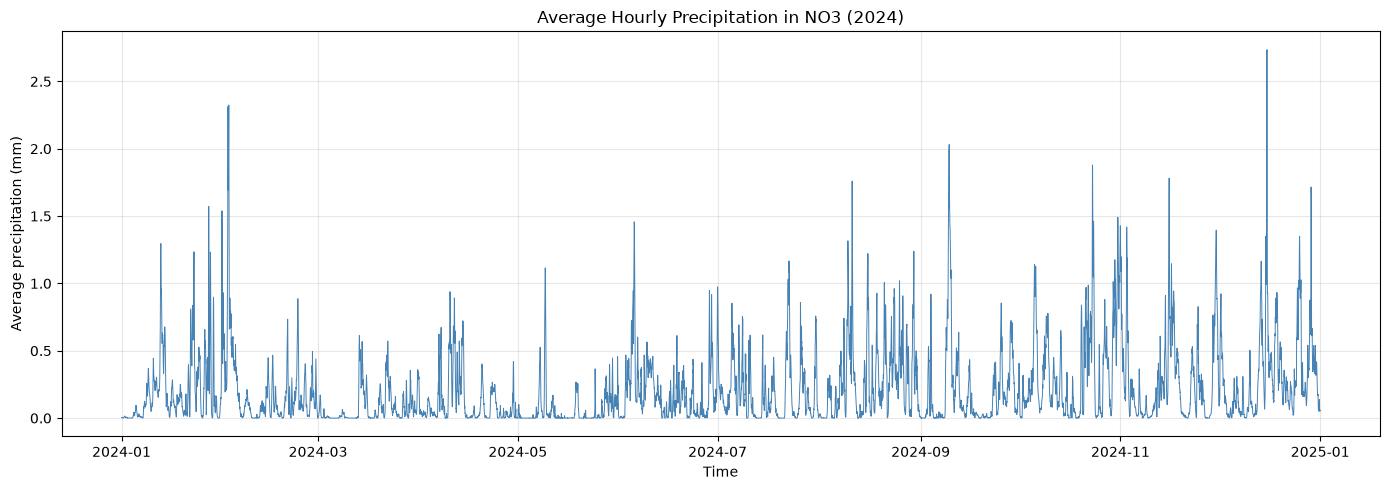

In [31]:

import matplotlib.pyplot as plt

# Plot the average hourly precipitation in NO3 during 2024
plt.figure(figsize=(14, 5))

plt.plot(
    NO3_hourly_precipitation["time"],
    NO3_hourly_precipitation["mean_precipitation"],
    color="steelblue",
    linewidth=0.7
)

# Add title and axis labels
plt.title("Average Hourly Precipitation in NO3 (2024)")
plt.xlabel("Time")
plt.ylabel("Average precipitation (mm)")

# Improve readability
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


The plot shows the average hourly precipitation across 1000 geographical locations in the NO3 electricity region during 2024. Precipitation varies considerably throughout the year, with several sharp peaks indicating periods of heavy rainfall. The hourly averages provide a regional precipitation time series for further analysis.

In [32]:

import numpy as np
from scipy.fft import dct, idct

# Get the average hourly precipitation values for NO3
precipitation_values = NO3_hourly_precipitation["mean_precipitation"].to_numpy()

# Convert the precipitation data into frequency components using DCT
dct_coefficients = dct(precipitation_values, norm="ortho")

# Set the cutoff for removing low-frequency components
cutoff = 30

# Copy the DCT coefficients to keep the original values unchanged
filtered_coefficients = dct_coefficients.copy()

# Remove the first 30 components, representing the slowest variations
filtered_coefficients[:cutoff] = 0

# Convert the remaining components back into a time series
precipitation_highpass = idct(filtered_coefficients, norm="ortho")

# Display the first five high-pass filtered values
print(precipitation_highpass[:5])


[-0.11688752 -0.11778376 -0.1177763  -0.11776518 -0.11795025]


In [33]:

# Calculate the median of all high-pass filtered precipitation values
median_precipitation = np.median(precipitation_highpass)

# Calculate the absolute distance from each value to the median
absolute_deviations = np.abs(precipitation_highpass - median_precipitation)

# Calculate the Median Absolute Deviation (MAD)
mad_precipitation = np.median(absolute_deviations)

# Convert MAD into a robust estimate of standard deviation
robust_std = 1.4826 * mad_precipitation

# Set the number of standard deviations for the SPC limits
n_std = 3

# Calculate the lower and upper SPC limits for filtered values
lower_limit = median_precipitation - n_std * robust_std
upper_limit = median_precipitation + n_std * robust_std

# Display the calculated statistics
print("Median:", median_precipitation)
print("MAD:", mad_precipitation)
print("Robust standard deviation:", robust_std)
print("Lower SPC limit:", lower_limit)
print("Upper SPC limit:", upper_limit)


Median: -0.05646152
MAD: 0.10259981
Robust standard deviation: 0.15211447
Lower SPC limit: -0.5128049
Upper SPC limit: 0.3998819


In [34]:

# Identify observations outside the SPC limits
outliers = (precipitation_highpass < lower_limit) | (precipitation_highpass > upper_limit)

# Count the number of detected outliers
number_of_outliers = np.sum(outliers)

# Calculate the percentage of outliers
outlier_percentage = (number_of_outliers / len(precipitation_highpass)) * 100

# Display the results
print("Total observations:", len(precipitation_highpass))
print("Number of outliers:", number_of_outliers)
print(f"Outlier percentage: {outlier_percentage:.2f}%")


Total observations: 8784
Number of outliers: 625
Outlier percentage: 7.12%


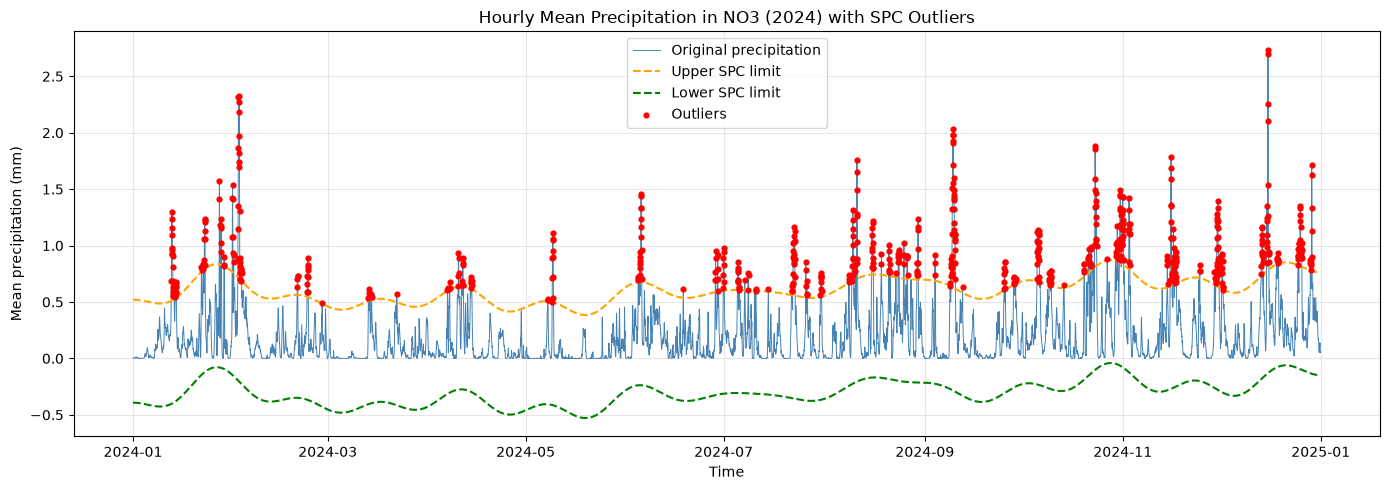

In [35]:

import matplotlib.pyplot as plt

# Recover the slow variations removed by the high-pass filter
baseline = precipitation_values - precipitation_highpass

# Convert the SPC limits to the original precipitation scale
lower_original = baseline + lower_limit
upper_original = baseline + upper_limit

# Create the figure
plt.figure(figsize=(14, 5))

# Plot the original precipitation values
plt.plot(NO3_hourly_precipitation["time"], precipitation_values,
         color="steelblue", linewidth=0.7, label="Original precipitation")

# Plot the SPC limits
plt.plot(NO3_hourly_precipitation["time"], upper_original,
         color="orange", linestyle="--", label="Upper SPC limit")

plt.plot(NO3_hourly_precipitation["time"], lower_original,
         color="green", linestyle="--", label="Lower SPC limit")

# Highlight detected outliers on the original data
plt.scatter(NO3_hourly_precipitation["time"][outliers],
            precipitation_values[outliers],
            color="red", s=12, label="Outliers", zorder=3)

# Add labels and formatting
plt.title("Hourly Mean Precipitation in NO3 (2024) with SPC Outliers")
plt.xlabel("Time")
plt.ylabel("Mean precipitation (mm)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


The DCT high-pass filter was applied to the hourly mean precipitation data for NO3 in 2024 to remove slow variations. Robust SPC was then used to identify unusually large deviations in the filtered data.

Using a cutoff of 30 DCT components and SPC limits based on three robust standard deviations, 625 out of 8,784 hourly observations (7.12%) were classified as outliers.

The detected outliers occur throughout the year, with several clusters of unusually high precipitation during certain periods. These observations represent statistical anomalies in short-term precipitation variations, but do not necessarily indicate extreme weather events.

#### 4.1.2 Comparing Cut Offs

In [36]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct, idct

def compare_cutoffs(precipitation_data, time_data, cutoffs=(30, 60, 105), n_std=3):

    # Convert precipitation data to a NumPy array
    values = np.asarray(precipitation_data)

    # Apply DCT to the original precipitation data
    coefficients = dct(values, norm="ortho")

    # Create a figure with one plot for each cutoff
    fig, axes = plt.subplots(len(cutoffs), 1, figsize=(14, 12), sharex=True)

    # Store the results for comparison
    results = []

    for ax, cutoff in zip(axes, cutoffs):

        # Remove the low-frequency DCT components
        filtered_coefficients = coefficients.copy()
        filtered_coefficients[:cutoff] = 0

        # Reconstruct the high-pass filtered precipitation
        highpass = idct(filtered_coefficients, norm="ortho")

        # Calculate robust SPC statistics
        median = np.median(highpass)
        mad = np.median(np.abs(highpass - median))
        robust_std = 1.4826 * mad

        # Calculate SPC limits
        lower_limit = median - n_std * robust_std
        upper_limit = median + n_std * robust_std

        # Identify outliers
        outliers = (highpass < lower_limit) | (highpass > upper_limit)

        # Count detected outliers
        count = np.sum(outliers)
        percentage = 100 * count / len(values)

        # Calculate SPC limits on the original precipitation scale
        baseline = values - highpass
        upper_original = baseline + upper_limit

        # Plot original precipitation
        ax.plot(time_data, values, color="steelblue",
                linewidth=0.7, label="Original precipitation")

        # Plot the upper SPC limit
        ax.plot(time_data, upper_original, color="orange",
                linestyle="--", label="Upper SPC limit")

        # Highlight outliers
        ax.scatter(np.asarray(time_data)[outliers], values[outliers],
                   color="red", s=12, label="Outliers", zorder=3)

        # Add plot labels
        ax.set_title(f"Cutoff = {cutoff} | Outliers = {count} ({percentage:.2f}%)")
        ax.set_ylabel("Precipitation (mm)")
        ax.grid(alpha=0.3)
        ax.legend()

        # Save results
        results.append({
            "Cutoff": cutoff,
            "Outliers": int(count),
            "Percentage (%)": round(percentage, 2)
        })

    # Add shared x-axis label
    axes[-1].set_xlabel("Time")
    plt.tight_layout()
    plt.show()

    return results


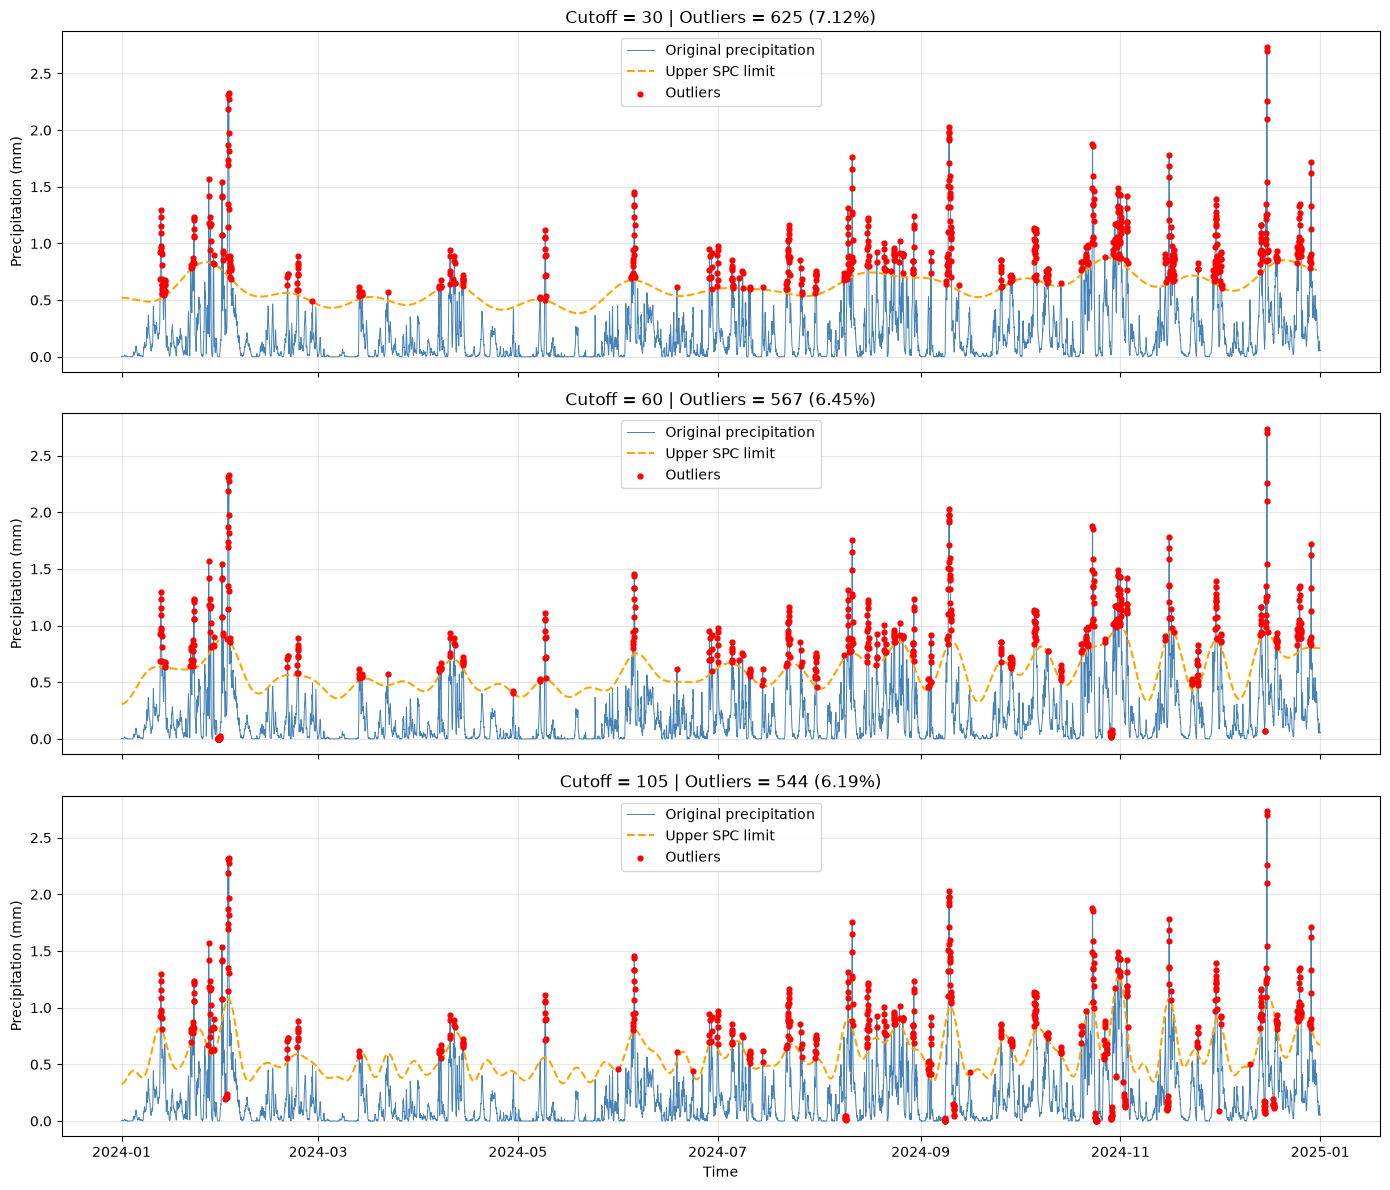

,Cutoff,Outliers,Percentage (%)
0,30,625,7.12
1,60,567,6.45
2,105,544,6.19


In [37]:

# Compare three DCT cutoff values for NO3 precipitation
cutoff_results = compare_cutoffs(
    precipitation_data=NO3_hourly_precipitation["mean_precipitation"],
    time_data=NO3_hourly_precipitation["time"],
    cutoffs=(30, 60, 105),
    n_std=3
)

# Display the comparison as a table
import pandas as pd

pd.DataFrame(cutoff_results)


### Comparison of DCT Cutoff Values

The analysis shows that the number of detected outliers changes depending on the DCT cutoff value.

With a cutoff of 30, 625 outliers (7.12%) were detected. Increasing the cutoff to 60 reduced the number to 567 (6.45%), while a cutoff of 105 resulted in 544 outliers (6.19%).

This happens because increasing the cutoff removes more low-frequency components, leaving only faster variations in the precipitation data. As a result, the values used for SPC analysis change, which affects which observations are classified as outliers.

However, fewer outliers do not necessarily mean that the method is more accurate. The appropriate cutoff depends on which variations are relevant to the analysis. Therefore, comparing different cutoff values helps us understand how sensitive the results are to this parameter.

#### 4.1.3 DCT Function - With Cut-off and Standard Deviation as Parameters

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct, idct

def detect_precipitation_outliers(data, cutoff=30, n_std=3):

    # Extract precipitation values and time
    values = data["mean_precipitation"].to_numpy()
    time = data["time"].to_numpy()

    # Apply DCT and remove low-frequency components
    coefficients = dct(values, norm="ortho")
    filtered = coefficients.copy()
    filtered[:cutoff] = 0

    # Reconstruct high-frequency variations
    highpass = idct(filtered, norm="ortho")

    # Calculate robust SPC limits using median and MAD
    median = np.median(highpass)
    mad = np.median(np.abs(highpass - median))
    robust_std = 1.4826 * mad

    lower_limit = median - n_std * robust_std
    upper_limit = median + n_std * robust_std

    # Identify outliers
    outliers = (highpass < lower_limit) | (highpass > upper_limit)

    # Calculate summary statistics
    count = int(np.sum(outliers))
    percentage = 100 * count / len(values)

    # Convert SPC limits back to the original precipitation scale
    baseline = values - highpass
    upper_original = baseline + upper_limit

    # Plot original precipitation and detected outliers
    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(time, values, color="steelblue",
            linewidth=0.7, label="Mean precipitation")

    ax.plot(time, upper_original, color="orange",
            linestyle="--", label="Upper SPC limit")

    ax.scatter(time[outliers], values[outliers],
               color="red", s=12, label="Outliers", zorder=3)

    ax.set_title("Precipitation Outliers in NO3 (2024) - DCT + SPC")
    ax.set_xlabel("Time")
    ax.set_ylabel("Mean precipitation (mm)")
    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    # Return plot and summary
    summary = {
        "DCT cutoff": cutoff,
        "Standard deviations": n_std,
        "Number of outliers": count,
        "Percentage (%)": round(percentage, 2)
    }

    return fig, summary

{'DCT cutoff': 30, 'Standard deviations': 3, 'Number of outliers': 625, 'Percentage (%)': 7.12}


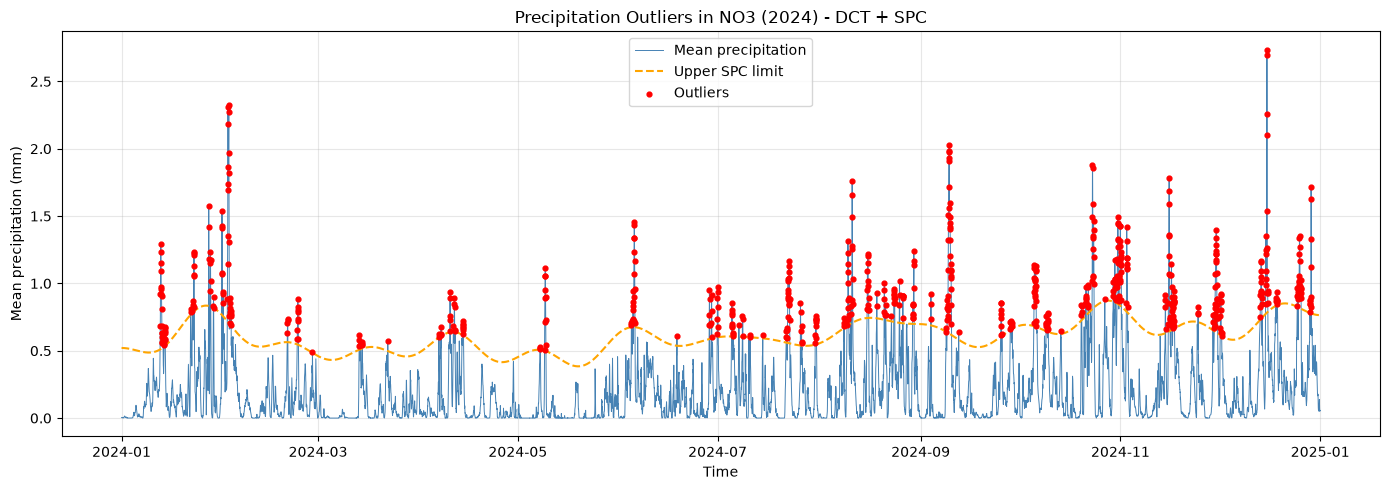

In [39]:
precipitation_fig, precipitation_summary = detect_precipitation_outliers(
    NO3_hourly_precipitation
)

print(precipitation_summary)
plt.show()

### 4.2 Temperature Anomalies: Local Outlier Factor (LOF)

#### 4.2.1 Reading loaded data and finding mean of temperature for each hour

In [40]:

# Read only the columns needed for temperature analysis
temperature_table = pq.read_table(
    combined_file,
    columns=["time", "temperature_2m"]
)

# Convert to a pandas DataFrame
temperature_data = temperature_table.to_pandas()

# Calculate mean temperature for each hour
NO3_hourly_temperature = (
    temperature_data
    .groupby("time")["temperature_2m"]
    .mean()
    .reset_index(name="mean_temperature")
)

# Display the first five rows
NO3_hourly_temperature.head()


,time,mean_temperature
0,2024-01-01 00:00:00+00:00,-3.358778
1,2024-01-01 01:00:00+00:00,-3.496228
2,2024-01-01 02:00:00+00:00,-3.467177
3,2024-01-01 03:00:00+00:00,-3.496177
4,2024-01-01 04:00:00+00:00,-3.439828


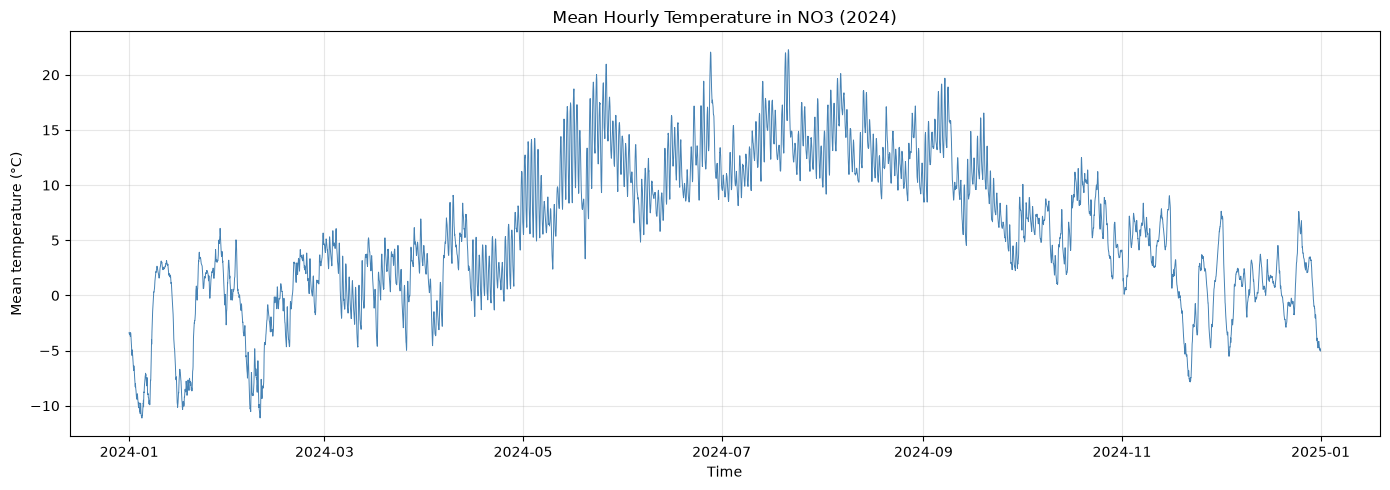

In [41]:

import matplotlib.pyplot as plt

# Plot the mean hourly temperature for NO3 in 2024
plt.figure(figsize=(14, 5))

plt.plot(
    NO3_hourly_temperature["time"],
    NO3_hourly_temperature["mean_temperature"],
    color="steelblue",
    linewidth=0.7
)

# Add title and axis labels
plt.title("Mean Hourly Temperature in NO3 (2024)")
plt.xlabel("Time")
plt.ylabel("Mean temperature (°C)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### 4.2.2 LOF on temperature (without time consideration)

In [42]:

from sklearn.neighbors import LocalOutlierFactor
import numpy as np

# Extract mean hourly temperature values
temperature_values = NO3_hourly_temperature[["mean_temperature"]].to_numpy()

# Create the LOF model
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.01
)

# Detect temperature anomalies
lof_labels = lof.fit_predict(temperature_values)

# Identify observations classified as anomalies
temperature_outliers = lof_labels == -1

# Count the detected anomalies
number_of_temperature_outliers = np.sum(temperature_outliers)

print(f"Number of anomalies: {number_of_temperature_outliers}")
print(f"Percentage: {100 * temperature_outliers.mean():.2f}%")


Number of anomalies: 88
Percentage: 1.00%


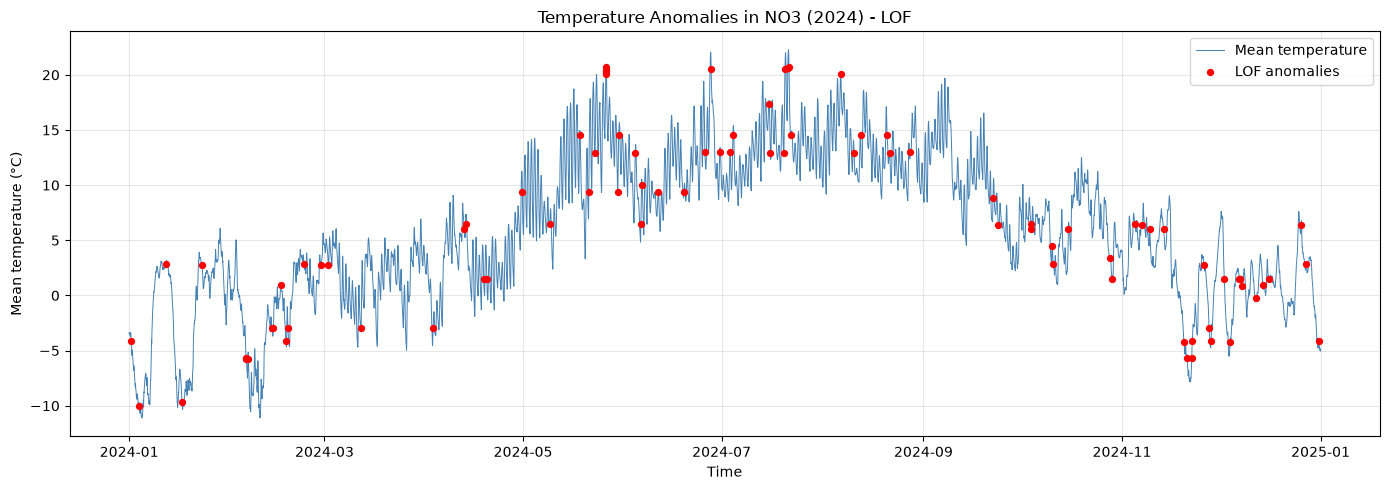

In [43]:
# Plot the original mean hourly temperature
plt.figure(figsize=(14, 5))

plt.plot(
    NO3_hourly_temperature["time"],
    NO3_hourly_temperature["mean_temperature"],
    color="steelblue",
    linewidth=0.7,
    label="Mean temperature"
)

# Highlight anomalies detected by LOF
plt.scatter(
    NO3_hourly_temperature.loc[temperature_outliers, "time"],
    NO3_hourly_temperature.loc[temperature_outliers, "mean_temperature"],
    color="red",
    s=18,
    label="LOF anomalies",
    zorder=3
)

# Add title and labels
plt.title("Temperature Anomalies in NO3 (2024) - LOF")
plt.xlabel("Time")
plt.ylabel("Mean temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### 4.2.3 LOF on temperature considering weekly time periods 

In [44]:

# Sort temperature observations by time
NO3_hourly_temperature = (
    NO3_hourly_temperature
    .sort_values("time")
    .reset_index(drop=True)
)

# Calculate a centered 7-day moving average
NO3_hourly_temperature["temperature_trend"] = (
    NO3_hourly_temperature["mean_temperature"]
    .rolling(window=7 * 24, center=True, min_periods=1)
    .mean()
)

# Calculate deviations from the local temperature trend
NO3_hourly_temperature["temperature_deviation"] = (
    NO3_hourly_temperature["mean_temperature"]
    - NO3_hourly_temperature["temperature_trend"]
)

# Display the results
NO3_hourly_temperature.head()


,time,mean_temperature,temperature_trend,temperature_deviation
0,2024-01-01 00:00:00+00:00,-3.358778,-7.216595,3.857817
1,2024-01-01 01:00:00+00:00,-3.496228,-7.246661,3.750434
2,2024-01-01 02:00:00+00:00,-3.467177,-7.276696,3.809518
3,2024-01-01 03:00:00+00:00,-3.496177,-7.311318,3.815141
4,2024-01-01 04:00:00+00:00,-3.439828,-7.348719,3.908891


In [45]:

from sklearn.neighbors import LocalOutlierFactor
import numpy as np

# Use deviations from the local temperature trend
temperature_values = NO3_hourly_temperature[
    ["temperature_deviation"]
].to_numpy()

# Apply LOF to the temperature deviations
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.01
)

lof_labels = lof.fit_predict(temperature_values)

# Identify anomalies
temperature_outliers = lof_labels == -1

# Summarize the detected anomalies
number_of_outliers = np.sum(temperature_outliers)
outlier_percentage = 100 * number_of_outliers / len(temperature_values)

print(f"Number of anomalies: {number_of_outliers}")
print(f"Percentage: {outlier_percentage:.2f}%")


Number of anomalies: 88
Percentage: 1.00%


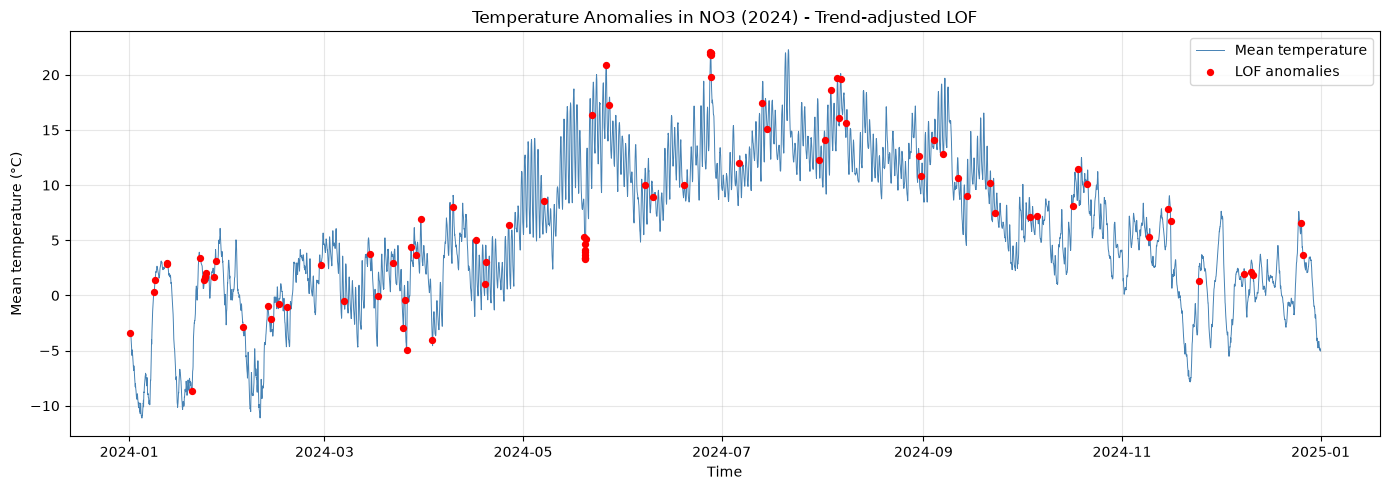

In [46]:

# Plot mean hourly temperature
plt.figure(figsize=(14, 5))

plt.plot(
    NO3_hourly_temperature["time"],
    NO3_hourly_temperature["mean_temperature"],
    color="steelblue",
    linewidth=0.7,
    label="Mean temperature"
)

# Highlight anomalies based on temperature deviations
plt.scatter(
    NO3_hourly_temperature.loc[temperature_outliers, "time"],
    NO3_hourly_temperature.loc[temperature_outliers, "mean_temperature"],
    color="red",
    s=18,
    label="LOF anomalies",
    zorder=3
)

# Add title and labels
plt.title("Temperature Anomalies in NO3 (2024) - Trend-adjusted LOF")
plt.xlabel("Time")
plt.ylabel("Mean temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### 4.2.4 Making a function for LOF on temperature 

In [47]:

from sklearn.neighbors import LocalOutlierFactor
import numpy as np
import matplotlib.pyplot as plt

def detect_temperature_anomalies(
    temperature_data,
    contamination=0.01,
    n_neighbors=20,
    window_days=7
):
    # Sort observations chronologically
    data = temperature_data.sort_values("time").copy()

    # Calculate a centered moving average
    window_hours = window_days * 24
    data["temperature_trend"] = (
        data["mean_temperature"]
        .rolling(window=window_hours, center=True, min_periods=1)
        .mean()
    )

    # Calculate deviations from the local trend
    data["temperature_deviation"] = (
        data["mean_temperature"] - data["temperature_trend"]
    )

    # Apply LOF to temperature deviations
    values = data[["temperature_deviation"]].to_numpy()

    lof = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=contamination
    )

    labels = lof.fit_predict(values)
    outliers = labels == -1

    # Calculate summary statistics
    count = int(np.sum(outliers))
    percentage = 100 * count / len(data)

    # Plot original temperature and detected anomalies
    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        data["time"],
        data["mean_temperature"],
        color="steelblue",
        linewidth=0.7,
        label="Mean temperature"
    )

    ax.scatter(
        data.loc[outliers, "time"],
        data.loc[outliers, "mean_temperature"],
        color="red",
        s=18,
        label="LOF anomalies",
        zorder=3
    )

    ax.set_title("Temperature Anomalies in NO3 (2024) - Trend-adjusted LOF")
    ax.set_xlabel("Time")
    ax.set_ylabel("Mean temperature (°C)")
    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    # Return plot and anomaly summary
    summary = {
        "Contamination": contamination,
        "Neighbors": n_neighbors,
        "Window (days)": window_days,
        "Number of anomalies": count,
        "Percentage (%)": round(percentage, 2)
    }

    return fig, summary


{'Contamination': 0.01, 'Neighbors': 20, 'Window (days)': 7, 'Number of anomalies': 88, 'Percentage (%)': 1.0}


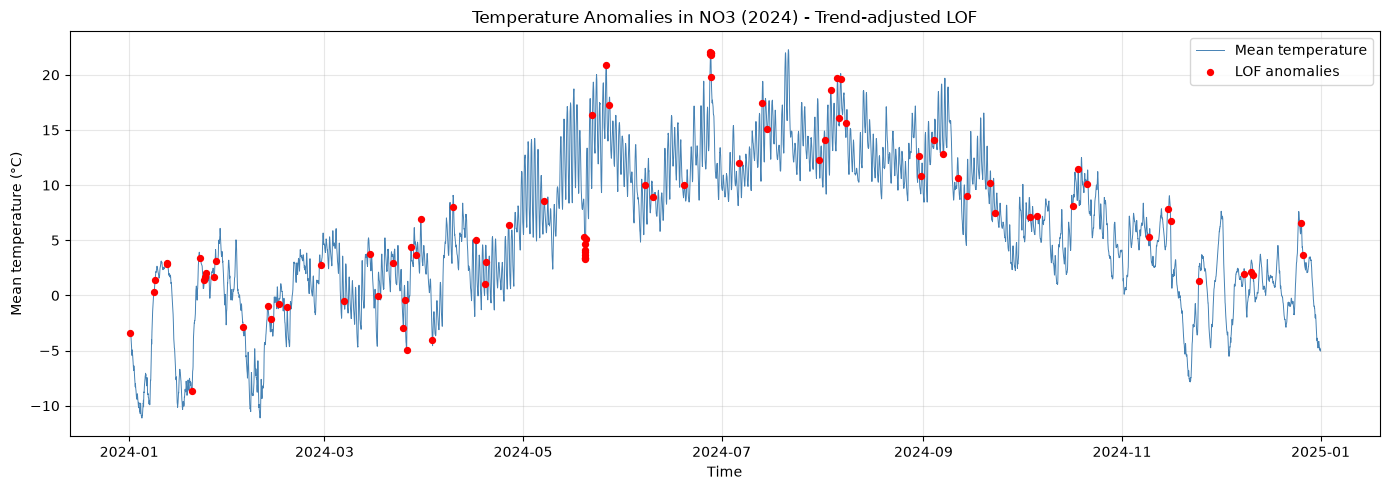

In [48]:

# Test the LOF function with default parameters
temperature_fig, temperature_summary = detect_temperature_anomalies(
    NO3_hourly_temperature
)

# Display the anomaly summary
print(temperature_summary)

# Display the plot
plt.show()


#### 4.2.5 LOF Analysis – Temperature Anomalies

Temperature varies throughout the year due to seasonal changes. Applying LOF directly to the temperature values would not account for when the measurements occurred.

To address this, a 7-day centered moving average was used to estimate the local temperature trend. The difference between the observed temperature and this trend was then calculated, and LOF was applied to these deviations rather than the original temperatures.

The LOF method identifies observations with unusually low local density compared to their nearest neighbors. The contamination parameter was set to 0.01, meaning that approximately 1% of the observations were classified as anomalies.

This approach helps identify unusual temperature deviations relative to the surrounding days. However, the detected anomalies are not necessarily measurement errors or extreme temperatures relative to historical seasonal averages.

## 5. Seasonal Trend Analysis

STL Analysis – Reservoir Fill Level 

The goal of STL decomposition of reservoir fill levels is to understand how much of the variation can be explained by long-term trends and recurring seasonal patterns, and how much remains unexplained by these two components (residuals).

The trend component represents longer-term changes in the general reservoir fill level, while the seasonal component represents patterns that repeat throughout the year. The residual component captures the remaining variation that is not accounted for by the trend or seasonal components.

#### 5.1 STL Analysis and plot

In [49]:
import pandas as pd
import requests

# Retrieve reservoir statistics from the NVE API
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(url, timeout=30)
response.raise_for_status()

# Convert the API response to a DataFrame
df_reservoir = pd.DataFrame(response.json())

# Convert dates to datetime
df_reservoir["dato_Id"] = pd.to_datetime(df_reservoir["dato_Id"])
# Sort reservoir data chronologically
df_reservoir = df_reservoir.sort_values("dato_Id").reset_index(drop=True)

# Create area labels, matching the Streamlit app
df_reservoir["area"] = (
    df_reservoir["omrType"]
    + df_reservoir["omrnr"].astype(str)
)

# Inspect the dataset
print("Number of observations:", len(df_reservoir))
print("Available areas:", sorted(df_reservoir["area"].unique()))

display(df_reservoir.head())

Number of observations: 14940
Available areas: ['EL1', 'EL2', 'EL3', 'EL4', 'EL5', 'NO0', 'VASS1', 'VASS2', 'VASS3']


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad,area
0,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869,EL1
1,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643,NO0
2,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525,VASS3
3,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041,VASS1
4,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349,EL3


In [50]:
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt

def plot_reservoir_stl(data, area="NO0", seasonal=13, trend=105, robust=True):
    """
    Perform STL decomposition of reservoir fill levels for a selected area.
    """

    # Select the area and sort chronologically
    area_data = data[data["area"] == area].sort_values("dato_Id").copy()

    # Use reservoir fill level as a percentage
    fill_level = area_data.set_index("dato_Id")["fyllingsgrad"] * 100

    # Perform STL decomposition
    stl = STL(
        fill_level,
        period=52, # Yearly
        seasonal=seasonal,
        trend=trend,
        robust=robust
    )

    result = stl.fit()

    # Plot the decomposition
    fig = result.plot()
    fig.set_size_inches(12, 9)
    fig.suptitle(f"STL Decomposition of Reservoir Fill Level – {area}", fontsize=14)
    fig.tight_layout()

    return fig

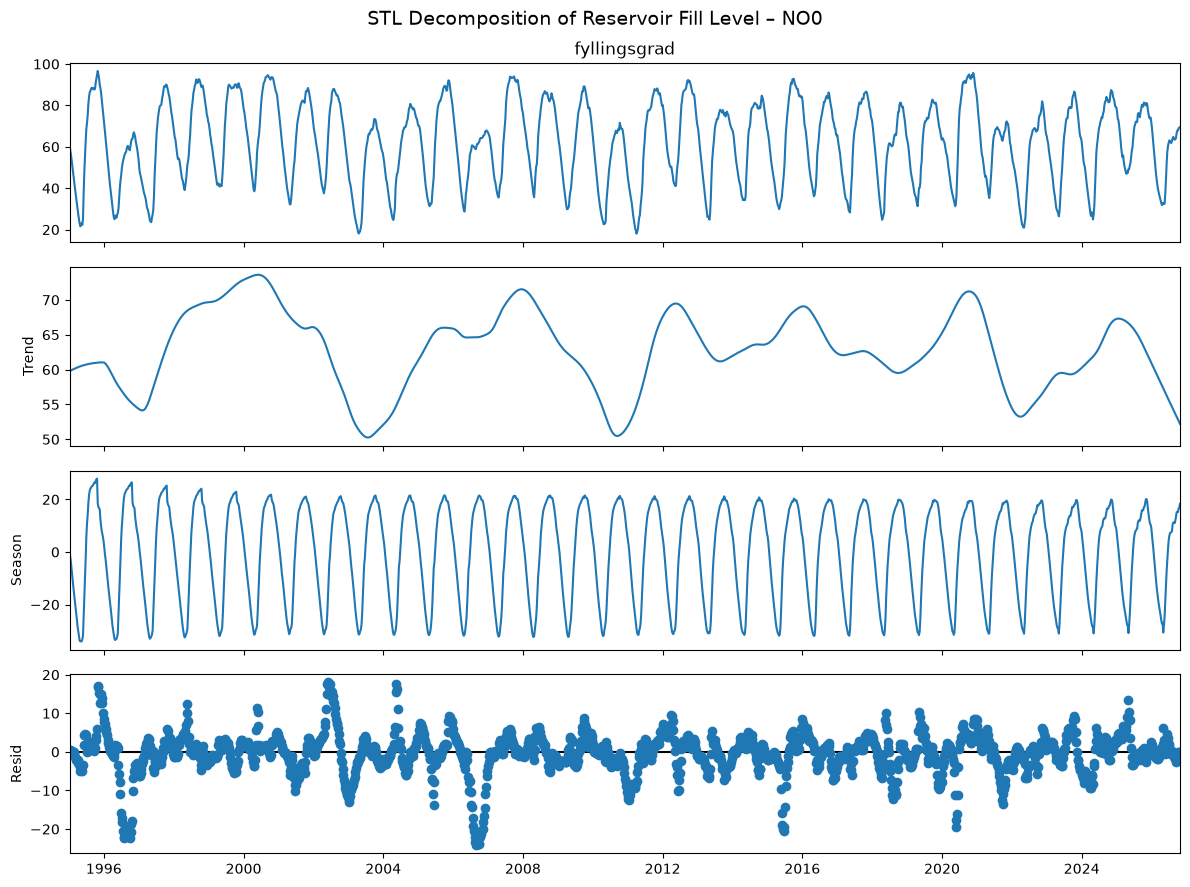

In [51]:
# Test STL decomposition for Norway
stl_fig = plot_reservoir_stl(
    df_reservoir,
    area="NO0"
)

plt.show()

#### 5.2 STL Analysis and Plot + Plot of Average Yearly Sesonal Patterns

In [52]:
def plot_reservoir_stl(data, area="NO0", seasonal=13, trend=105, robust=True):
    """
    Perform STL decomposition and visualize the average annual seasonal pattern.
    """

    # Select the area and sort chronologically
    area_data = data[data["area"] == area].sort_values("dato_Id").copy()

    # Convert reservoir fill level to percentage
    fill_level = area_data.set_index("dato_Id")["fyllingsgrad"] * 100

    # Perform STL decomposition
    stl = STL(
        fill_level,
        period=52,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    )

    result = stl.fit()

    # Plot the STL decomposition
    fig_stl = result.plot()
    fig_stl.set_size_inches(12, 9)
    fig_stl.suptitle(f"STL Decomposition – {area}", fontsize=14)
    fig_stl.tight_layout()

    # Calculate the average seasonal component for each week
    seasonal_data = pd.DataFrame({
        "week": fill_level.index.isocalendar().week.to_numpy(),
        "seasonal": result.seasonal.to_numpy()
    })

    average_seasonal = (
        seasonal_data[seasonal_data["week"] <= 52]
        .groupby("week")["seasonal"]
        .mean()
    )

    # Plot the typical annual seasonal pattern
    fig_annual, ax = plt.subplots(figsize=(12, 5))

    ax.plot(average_seasonal.index, average_seasonal.values)

    ax.set_title(f"Average Annual Seasonal Pattern – {area}")
    ax.set_xlabel("Week of the year")
    ax.set_ylabel("Seasonal effect (percentage points)")
    ax.set_xticks(range(1, 53, 4))
    ax.grid(alpha=0.3)

    fig_annual.tight_layout()

    return fig_stl, fig_annual

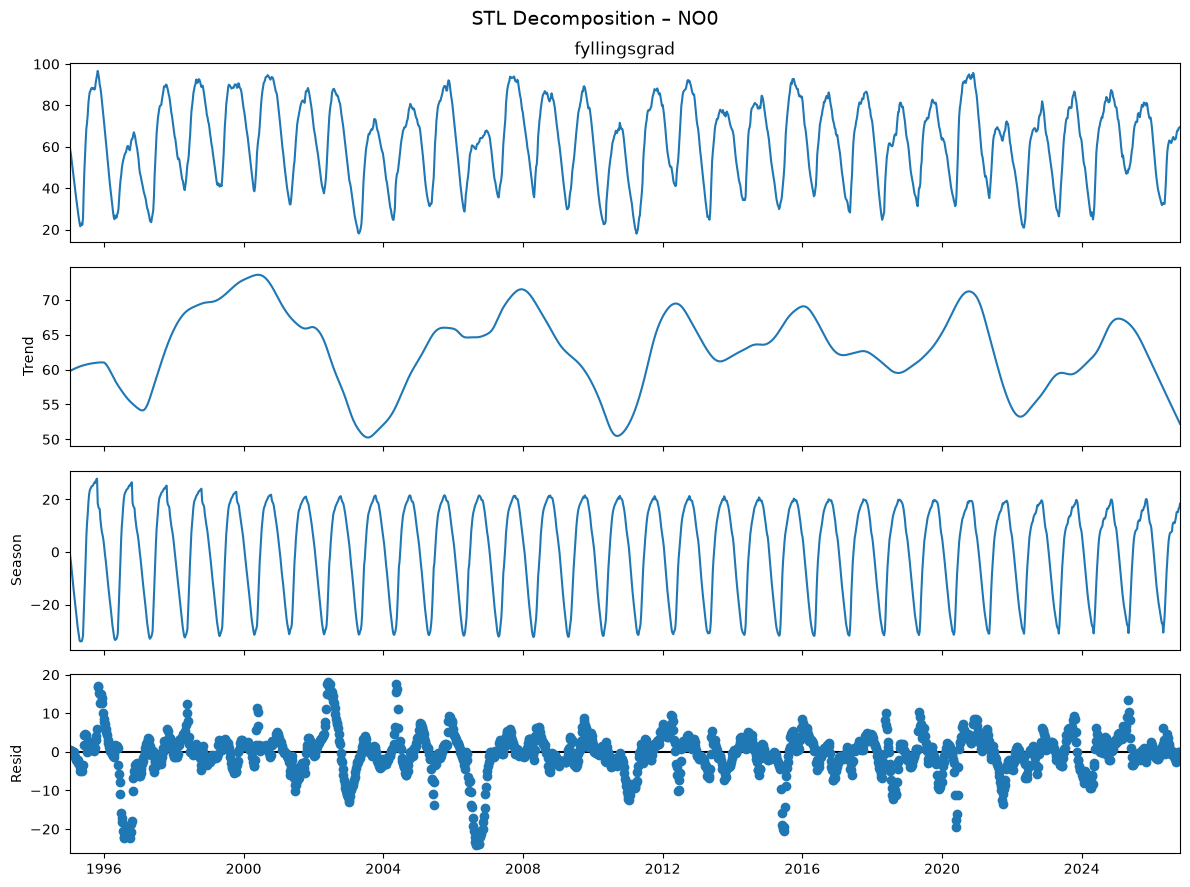

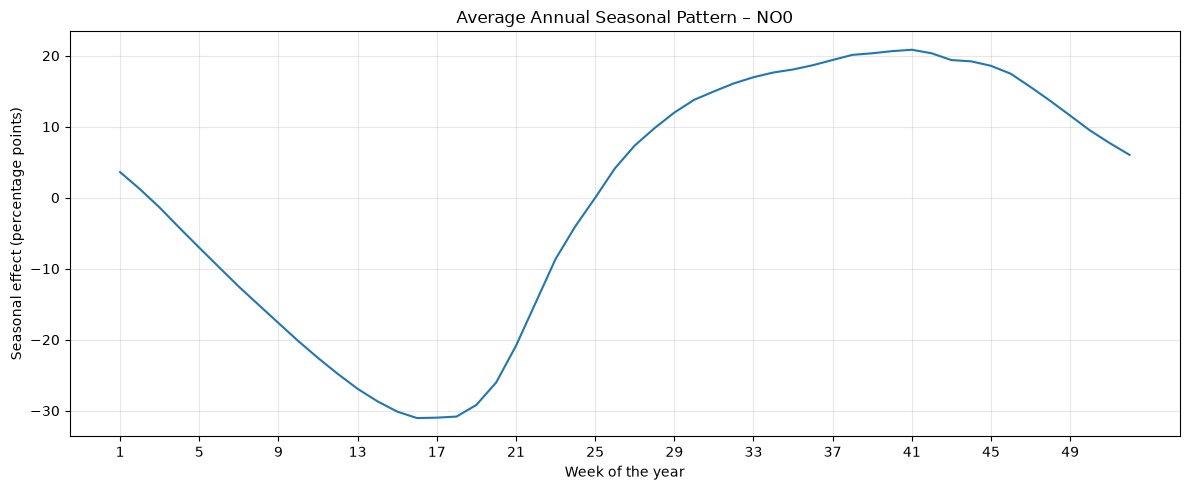

In [53]:
# Test STL decomposition and annual seasonal pattern
stl_fig, annual_fig = plot_reservoir_stl(
    df_reservoir,
    area="NO0"
)

plt.show()

#### Analysis of Average Annual Seasonal Pattern – Reservoir Fill Level

The average seasonal component from the STL decomposition was calculated for each week of the year using historical reservoir data for Norway (NO0).

The results show a clear annual pattern. The seasonal effect reaches its lowest point around weeks 16–18 (approximately −31 percentage points) and its highest point around weeks 40–41 (approximately +21 percentage points).

This suggests that Norwegian reservoir fill levels are typically lowest during spring and highest during autumn. The pattern is consistent with seasonal changes in snowmelt, water inflow and electricity production.

The graph represents the average seasonal effect relative to the estimated trend, rather than the actual reservoir fill level.

## 6. Spectogram Analysis

#### 6.1 What is a Sprectogram Analysis

A spectrogram shows how the frequency content of a time series changes over time. It can be used to identify recurring patterns and examine whether their strength changes throughout the observation period.

For reservoir fill levels, a spectrogram can help identify annual seasonal cycles and investigate how strongly these cycles appear in different years.

#### 6.2 Code and plot for Spectogram Analysis

In [54]:
from scipy.signal import spectrogram

def plot_reservoir_spectrogram(data, area="NO0", window_length=104, overlap=52):
    """
    Create a spectrogram of weekly reservoir fill levels
    for a selected area.
    """

    # Select the chosen reservoir area and sort by date
    area_data = data[data["area"] == area].sort_values("dato_Id").copy()

    # Convert reservoir fill levels to percentages
    fill_level = area_data["fyllingsgrad"].to_numpy() * 100

    # Calculate the spectrogram using weekly observations
    # fs=1 means one observation per week
    frequencies, times, power = spectrogram(
        fill_level,
        fs=1,
        window="hann",
        nperseg=window_length,
        noverlap=overlap,
        detrend="linear"
    )

    # Convert frequencies to cycles per year
    frequencies_per_year = frequencies * 52

    # Convert power to decibels for easier visualization
    power_db = 10 * np.log10(power + 1e-12)

    # Create the spectrogram plot
    fig, ax = plt.subplots(figsize=(12, 6))

    mesh = ax.pcolormesh(
        times / 52 + area_data["dato_Id"].dt.year.iloc[0],
        frequencies_per_year,
        power_db,
        shading="auto",
        cmap="viridis"
    )

    # Add a colorbar to show the strength of each frequency
    fig.colorbar(mesh, ax=ax, label="Power (dB)")

    # Label the axes and add a title
    ax.set_title(f"Spectrogram of Reservoir Fill Level – {area}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Frequency (cycles per year)")

    # Highlight the expected annual seasonal frequency
    ax.axhline(1, color="red", linestyle="--", label="Annual cycle")
    ax.legend()

    fig.tight_layout()

    return fig

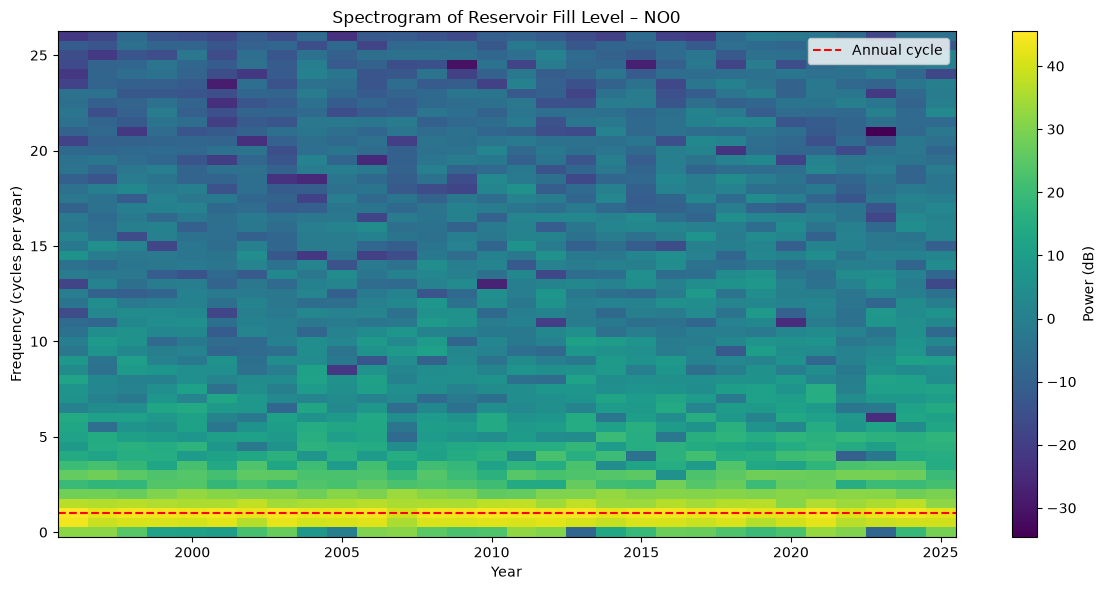

In [55]:
# Test the spectrogram for national reservoir data
spectrogram_fig = plot_reservoir_spectrogram(
    df_reservoir,
    area="NO0"
)

plt.show()

The red line shows what frecuency we are interested in analysing (yearly variation), while the color (here yellow) shows how strong the yearly pattern is at this frequency.

#### 6.3 Interpretation of the Spectrogram



The spectrogram shows a strong frequency component around 1 cycle per year, indicating a clear annual seasonal pattern in Norwegian reservoir fill levels.

This annual pattern remains visible throughout the observation period, suggesting that seasonal variations have been a consistent feature of reservoir fill levels over time.

Higher frequencies generally show lower power, indicating that shorter recurring cycles are less dominant.

These findings support the STL analysis, which also identified a strong annual seasonal pattern in reservoir fill levels. While STL shows how fill levels typically change throughout the year, the spectrogram confirms the frequency and persistence of this seasonal variation.

## 8. Project Log